<a href="https://colab.research.google.com/github/JulyAtaides/IA_-KADIDJA-/blob/main/atividades/atividade-07-aprendizado-supervisionado/fila_de_cadastros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 7 — Fila de cadastros

Disciplina: Inteligência Artificial, Linguagens Formais e Autômatos
Professora: Kadidja Valéria
Aluna: Julyane Ataides, turma N1
Aula 13, 09/11/2026

## Por que eu escolhi esse problema

No squad 5 eu fiquei com o cadastro de usuários e a tela em que o administrador valida ou recusa
os cadastros (BL-11 e BL-12). Então fazia sentido usar isso na atividade.

Funciona assim no nosso sistema: a pessoa se cadastra com o e-mail `@cs.udf.edu.br` e o cadastro
fica como "não validado". O administrador tem uma lista desses cadastros e, para cada um, ou valida
(escolhendo pelo menos um perfil) ou recusa (escrevendo o motivo, que vai por e-mail para a pessoa).
Se ninguém mexer em 30 dias, o próprio sistema apaga o cadastro.

O que eu quis fazer: um modelo que dá um palpite (`validado` ou `recusado`) olhando os dados do
cadastro, e umas regras que usam esse palpite junto com uma informação que só o administrador tem,
que é se ele já confirmou que a pessoa trabalha na faculdade.

## Leitura do guia da IBM

**1. O que é aprendizado de máquina?**
É quando o computador aprende sozinho olhando exemplos, em vez de alguém escrever todas as regras. Ele acha um padrão nos dados e depois usa esse padrão em dados novos.

**2. O que caracteriza o aprendizado supervisionado?**
Os exemplos já vêm com a resposta junto (o guia chama de dados rotulados). É tipo estudar com gabarito do lado: o modelo vai comparando o que ele acha com a resposta certa e se ajustando.

**3. O que são atributos e rótulos?**
Atributos são as informações que descrevem cada caso, no meu notebook o nome e o e-mail transformados em números. O rótulo é a resposta que eu quero que ele aprenda, aqui se o cadastro foi validado ou recusado.

**4. Como classificação difere de regressão?**
Na classificação a resposta é uma categoria (validado ou recusado). Na regressão é um número, por exemplo quantos dias o cadastro vai ficar esperando.

**5. Por que separar treino e teste?**
Porque testar usando as linhas que ele já viu no treino seria igual fazer a prova com as mesmas questões da lista: dá para tirar 10 sem ter entendido nada. Separando, eu vejo como ele se sai com casos que nunca viu.

## Parte 1 — Montando os dados

Antes de tudo, as bibliotecas (no Colab já vem tudo):

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Tudo carregado!")

Tudo carregado!


Cada linha é um cadastro que já foi analisado. Escolhi três colunas que o administrador consegue
ver na lista:

- `palavras_nome` — quantas palavras tem o nome completo
- `email_tem_nome` — 1 se antes do @ dá para ver o nome da pessoa, 0 se não dá
- `numeros_email` — quantos números aparecem antes do @

e a coluna `decisao`, que é o que eu quero que o modelo aprenda.

Os 20 cadastros são inventados por mim. O sistema ainda não tem cadastros de verdade, e mesmo se
tivesse eu não ia usar nome e e-mail de ninguém, só essas contagens. A regra que usei para decidir
cada linha foi: se o nome tem uma palavra só ou o e-mail não tem o nome da pessoa, recusado; senão,
validado. A única que fura isso é a linha 20, que é um e-mail de setor (tipo `coord.engsoft`) que foi
validado mesmo sem nome, porque o administrador sabia que era da coordenação.

In [2]:
dados = pd.DataFrame({
    "palavras_nome":  [3, 4, 2, 5, 3, 4, 3, 2, 4, 3,    1, 3, 1, 2, 4, 1, 3, 2, 1, 2],
    "email_tem_nome": [1, 1, 1, 1, 1, 1, 1, 1, 1, 0,    1, 0, 0, 0, 0, 1, 0, 0, 0, 0],
    "numeros_email":  [0, 0, 2, 0, 1, 0, 0, 3, 0, 2,    0, 3, 4, 6, 2, 1, 5, 0, 3, 0],
    "decisao": ["validado"] * 9 + ["recusado"] * 10 + ["validado"],
})
dados.index = dados.index + 1   # numerar a partir de 1

print(dados.to_string())
print()
print(dados["decisao"].value_counts())

dados.to_csv("dataset_fila_de_cadastros.csv", index_label="linha")

    palavras_nome  email_tem_nome  numeros_email   decisao
1               3               1              0  validado
2               4               1              0  validado
3               2               1              2  validado
4               5               1              0  validado
5               3               1              1  validado
6               4               1              0  validado
7               3               1              0  validado
8               2               1              3  validado
9               4               1              0  validado
10              3               0              2  recusado
11              1               1              0  recusado
12              3               0              3  recusado
13              1               0              4  recusado
14              2               0              6  recusado
15              4               0              2  recusado
16              1               1              1  recusa

## Parte 2 — Treinando e vendo se acertou

Separei 5 cadastros para testar e deixei 15 para o treino. O `stratify` serve para não cair, por
exemplo, só recusado no teste, e o `random_state` para a divisão sair igual toda vez que eu rodar.

In [3]:
entradas = ["palavras_nome", "email_tem_nome", "numeros_email"]
X = dados[entradas]
y = dados["decisao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"{len(X_treino)} para treinar e {len(X_teste)} para testar")
print("Ficaram no teste as linhas", list(sorted(X_teste.index)))

15 para treinar e 5 para testar
Ficaram no teste as linhas [5, 8, 13, 14, 17]


Agora a árvore. Deixei `max_depth=2` para ela fazer no máximo duas perguntas, senão fica difícil
de ler.

Acurácia: 100.0%
          validado  recusado
validado         2         0
recusado         0         3


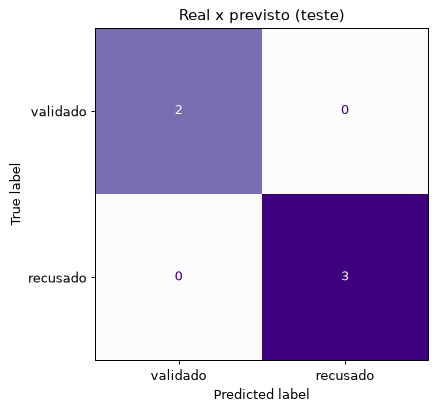

O que a árvore aprendeu:
|--- email_tem_nome <= 0.50
|   |--- numeros_email <= 1.00
|   |   |--- class: recusado
|   |--- numeros_email >  1.00
|   |   |--- class: recusado
|--- email_tem_nome >  0.50
|   |--- palavras_nome <= 1.50
|   |   |--- class: recusado
|   |--- palavras_nome >  1.50
|   |   |--- class: validado



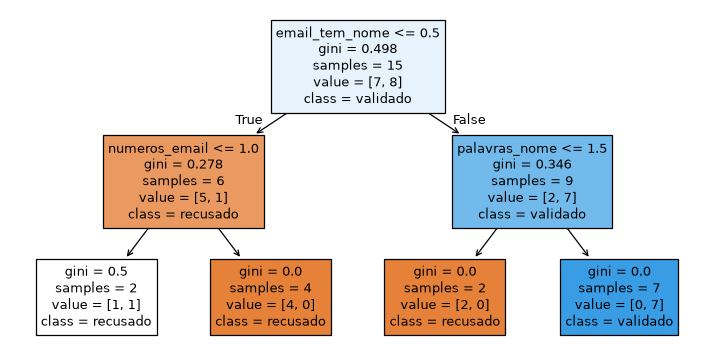

In [4]:
arvore = DecisionTreeClassifier(max_depth=2, random_state=42)
arvore.fit(X_treino, y_treino)
previsto = arvore.predict(X_teste)

print(f"Acurácia: {accuracy_score(y_teste, previsto):.1%}")

ordem = ["validado", "recusado"]
matriz = confusion_matrix(y_teste, previsto, labels=ordem)
print(pd.DataFrame(matriz, index=ordem, columns=ordem))

ConfusionMatrixDisplay(matriz, display_labels=ordem).plot(cmap="Purples", colorbar=False)
plt.title("Real x previsto (teste)")
plt.show()

print("O que a árvore aprendeu:")
print(export_text(arvore, feature_names=entradas))

plt.figure(figsize=(10, 5))
plot_tree(arvore, feature_names=entradas, class_names=list(arvore.classes_), filled=True)
plt.show()

Acertou os 5 do teste (linhas 5, 8, 13, 14 e 17): 2 validados e 3 recusados, tudo na diagonal da matriz.
Fiquei desconfiada de dar 100%, e faz sentido: são poucos casos e os dados seguem uma regra bem simples
que eu mesma criei.

Lendo a árvore de cima para baixo:

1. primeiro ela pergunta se o e-mail tem o nome da pessoa (`email_tem_nome <= 0.5`). Se não tem, já vai para recusado;
2. se tem, ela olha o nome: com uma palavra só (`palavras_nome <= 1.5`) é recusado, com mais é validado.

Do lado esquerdo ela ainda fez uma pergunta sobre `numeros_email`, mas os dois lados deram recusado. Um
desses grupos ficou com 2 cadastros, um de cada tipo (um deles é a linha 20), e no empate ela escolheu
recusado. Ou seja, a linha 20 estava no treino e mesmo assim a árvore erraria ela.

## Parte 3 — As regras

Aqui é a parte de sistema especialista. Juntei o palpite do modelo com o que o administrador
informa e montei uma tabelinha de 4 combinações:

| | vínculo confirmado | vínculo não confirmado |
|:--|:--|:--|
| modelo diz validado | R1: validar e escolher o perfil | R2: confirmar com a coordenação primeiro |
| modelo diz recusado | R3: falar com a pessoa antes de decidir | R4: recusar escrevendo o motivo |

A R1 e a R4 eu tirei do que a gente já programou no squad (`validar_cadastro` não deixa validar sem
perfil e `recusar_cadastro` não deixa recusar sem motivo). A R2 e a R3 eu inventei para o
administrador não confiar cegamente no modelo.

In [5]:
regras = [
    {"id": "R1", "previsao": "validado", "vinculo_confirmado": True,
     "acao": "Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado)."},
    {"id": "R2", "previsao": "validado", "vinculo_confirmado": False,
     "acao": "Confirmar com a coordenação se a pessoa é da faculdade antes de validar."},
    {"id": "R3", "previsao": "recusado", "vinculo_confirmado": True,
     "acao": "Falar com a pessoa para conferir nome e e-mail antes de decidir."},
    {"id": "R4", "previsao": "recusado", "vinculo_confirmado": False,
     "acao": "Recusar informando o motivo (o cadastro é apagado e a pessoa recebe o motivo por e-mail)."},
]

def motor(previsao, vinculo_confirmado):
    for regra in regras:
        if regra["previsao"] == previsao and regra["vinculo_confirmado"] == vinculo_confirmado:
            return regra
    raise ValueError("Nenhuma regra serve para esses fatos.")

E a função que junta as duas coisas. Ela também calcula quantos dias faltam para o cadastro ser
apagado sozinho, usando o mesmo prazo de 30 dias que está no `contas/services.py`.

In [6]:
DIAS_PARA_VALIDAR = 30   # o mesmo valor do squad 5 (RN-36)

def analisar_cadastro(palavras_nome, email_tem_nome, numeros_email, dias_na_fila, vinculo_confirmado):
    if palavras_nome < 1 or numeros_email < 0 or email_tem_nome not in (0, 1):
        raise ValueError("Confira os dados do cadastro.")
    if not isinstance(vinculo_confirmado, bool):
        raise ValueError("vinculo_confirmado tem que ser True ou False.")

    caso = pd.DataFrame([{"palavras_nome": palavras_nome, "email_tem_nome": email_tem_nome,
                          "numeros_email": numeros_email}])
    previsao = arvore.predict(caso)[0]          # 1) o modelo prevê
    regra = motor(previsao, vinculo_confirmado)  # 2) a previsão vira fato e o motor escolhe a regra

    dias_restantes = DIAS_PARA_VALIDAR - dias_na_fila
    if dias_restantes <= 5:
        prazo = f"Atenção: faltam {dias_restantes} dia(s) para o cadastro ser apagado automaticamente."
    else:
        prazo = f"Faltam {dias_restantes} dias para o prazo de 30 dias."

    return {
        "previsao": previsao,
        "regra": regra["id"],
        "recomendacao": regra["acao"],
        "por_que": f"previsão = {previsao}; vínculo confirmado = {vinculo_confirmado}",
        "prazo": prazo,
    }

## Parte 4 — Testando

Três cadastros que não estão na tabela:

In [7]:
novos = [
    # (palavras do nome, e-mail tem nome?, números no e-mail, dias na fila, vínculo confirmado?)
    (3, 1, 0, 4,  True),
    (4, 1, 1, 12, False),
    (1, 0, 4, 27, False),
]
for i, cadastro in enumerate(novos, 1):
    print(f"\nCADASTRO {i}: {cadastro}")
    for chave, valor in analisar_cadastro(*cadastro).items():
        print(f"  {chave}: {valor}")


CADASTRO 1: (3, 1, 0, 4, True)
  previsao: validado
  regra: R1
  recomendacao: Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado).
  por_que: previsão = validado; vínculo confirmado = True
  prazo: Faltam 26 dias para o prazo de 30 dias.

CADASTRO 2: (4, 1, 1, 12, False)
  previsao: validado
  regra: R2
  recomendacao: Confirmar com a coordenação se a pessoa é da faculdade antes de validar.
  por_que: previsão = validado; vínculo confirmado = False
  prazo: Faltam 18 dias para o prazo de 30 dias.

CADASTRO 3: (1, 0, 4, 27, False)
  previsao: recusado
  regra: R4
  recomendacao: Recusar informando o motivo (o cadastro é apagado e a pessoa recebe o motivo por e-mail).
  por_que: previsão = recusado; vínculo confirmado = False
  prazo: Atenção: faltam 3 dia(s) para o cadastro ser apagado automaticamente.


O que aconteceu em cada um:

- cadastro 1: nome e e-mail normais e vínculo já confirmado. O modelo disse validado e caiu na R1.
- cadastro 2: dados normais também, mas o administrador ainda não confirmou o vínculo. Caiu na R2, que manda confirmar antes. Ainda faltam 18 dias, então tem tempo.
- cadastro 3: nome de uma palavra e e-mail sem nome, modelo disse recusado e sem vínculo confirmado caiu na R4. Esse está há 27 dias na fila, então apareceu o aviso de que faltam só 3 dias para ele sumir.

Por último, peguei o cadastro 2 e só troquei a resposta do administrador sobre o vínculo:

In [8]:
antes = analisar_cadastro(4, 1, 1, 12, False)
depois = analisar_cadastro(4, 1, 1, 12, True)
print("previsão:", antes["previsao"], "->", depois["previsao"])
print("regra:   ", antes["regra"], "->", depois["regra"])
print("antes: ", antes["recomendacao"])
print("depois:", depois["recomendacao"])

previsão: validado -> validado
regra:    R2 -> R1
antes:  Confirmar com a coordenação se a pessoa é da faculdade antes de validar.
depois: Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado).


Os dados do cadastro são os mesmos, então o palpite do modelo continua `validado`. O que fez a
recomendação mudar de R2 para R1 foi a resposta do administrador, que entra direto nas regras e
nem passa pelo modelo.

## Conclusão

Deu para ver bem a diferença entre as duas partes. A árvore aprendeu sozinha, olhando os 15
cadastros de treino, que e-mail sem nome e nome de uma palavra costumam ser recusados. Já as regras
fui eu que escrevi, e são elas que decidem o que o administrador faz. O palpite do modelo é só mais
um fato que as regras usam, do mesmo jeito que a "dificuldade em lógica" no exemplo da aula.

Mas tem bastante limitação. Acertar 5 de 5 parece ótimo, só que são 5 casos e fui eu que inventei
os dados com uma regra simples, então qualquer coisa ia acertar. O caso diferente (o e-mail de setor)
só aparece uma vez e o modelo não aprende ele. E o que mais me preocupou: tem gente que tem nome curto
de verdade, ou nome estrangeiro registrado diferente, e um sistema desses podia acabar recusando
essas pessoas. Por isso eu não deixaria o modelo decidir nada sozinho, a última palavra tem que ser
do administrador.

Sobre dados pessoais, eu tomei cuidado de não usar o nome nem o e-mail em si, só contagens, e o
nosso sistema já apaga cadastro parado em 30 dias justamente para não guardar dado sem motivo.

Material que usei: guia de aprendizado de máquina da IBM, documentação do scikit-learn
(`DecisionTreeClassifier` e `train_test_split`), notebook e slides da aula 13 e os documentos do
squad 5 (`docs/requirements.md` e `contas/services.py`).